# Demonstration: Optimal Anisotropic Growth Calibration in Bilayer Zigzag Forming
**Computational Solid Mechanics & Bayesian Optimization for Sheet Forming**

---

### Overview
This interactive notebook demonstrates the publication deliverables for the **PSM2025-zigzag** project:
1. **Mechanical Problem**: Modeling plastic deformation induced by an English wheel / sequential roller toolpath via an anisotropic bilayer eigenstrain shell formulation.
2. **Global Optimal Parameters**: The 4-parameter growth law ($g_{\text{top}}, g_{\text{bottom}}, \text{ortho}_{\text{top}}, \text{ortho}_{\text{bottom}}$) calibrated on **Run 6** via Bayesian Optimization (Attempt 153).
3. **Rigorous Metric**: Material-frame rigid alignment ($SO(3)$ Kabsch) and reference dual-area weighted symmetric distance ($L_{\text{sym}}$).
4. **Independent Validation**: Forward transfer to **Run 9** without parameter tuning.
5. **Visualizations**: 2D toolpath/deformation profiles and 3D spatial isometric warpage.


In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Ensure repository root is on path
REPO_ROOT = Path("..").resolve() if Path("..").joinpath("calibration").exists() else Path(".").resolve()
sys.path.insert(0, str(REPO_ROOT))

print("Repository root:", REPO_ROOT)
print("Modules imported successfully.")


Repository root: /gpfs/projects/p33082/PSM2025-zigzag
Modules imported successfully.


## 1. Optimal Calibrated Parameters (Attempt 153)
The 4-dimensional optimization space governs the differential growth tensor across the bilayer shell:
- **$g_{\text{top}}$**: Magnitude of in-plane growth in the top layer.
- **$g_{\text{bottom}}$**: Magnitude of in-plane growth in the bottom layer.
- **$\text{ortho}_{\text{top}}$**: Orthotropy ratio of the top layer (longitudinal vs transverse).
- **$\text{ortho}_{\text{bottom}}$**: Orthotropy ratio of the bottom layer.

Below, we load the verified optimization results from `Attempt 153` and inspect the parameters.


In [1]:
r6_path = REPO_ROOT / "run/run6_expanded_bo/evaluations/attempt_0153/result.json"
r9_path = REPO_ROOT / "run/run9_transfer_expanded/evaluations/attempt_9901/result.json"

with open(r6_path) as f:
    r6_data = json.load(f)
with open(r9_path) as f:
    r9_data = json.load(f)

params = r6_data["parameters"]
df_params = pd.DataFrame([
    {"Parameter": "Growth Top (g_top)", "Value": f"{params['gtop']:.6e}", "Physical Role": "Top layer longitudinal expansion"},
    {"Parameter": "Growth Bottom (g_bot)", "Value": f"{params['gbot']:.6e}", "Physical Role": "Bottom layer expansion"},
    {"Parameter": "Orthotropy Top", "Value": f"{params['ortho_top']:.4f}", "Physical Role": "Strong directional anisotropy"},
    {"Parameter": "Orthotropy Bottom", "Value": f"{params['ortho_bottom']:.4f}", "Physical Role": "Transverse Poisson-like coupling"}
])
df_params


Parameter          Value                         Physical Role
0      Growth Top (g_top)   2.707847e-04      Top layer longitudinal expansion
1   Growth Bottom (g_bot)   3.459647e-05                Bottom layer expansion
2          Orthotropy Top        -0.6245          Strong directional anisotropy
3        Orthotropy Bottom         0.2490    Transverse Poisson-like coupling


## 2. Quantitative Metric Formulation
The objective function evaluates the shape agreement between experimental 3D scans and C++ simulation meshes:
1. **Material-frame Rigid Alignment**: Closed-form $SO(3)$ Kabsch rotation aligns target scan coordinates to the simulation frame using boundary and symmetry constraints.
2. **Reference Dual-Area Quadrature**: Vertices on the discrete shell mesh carry non-uniform Voronoi dual areas $w_j = A_j / \sum A_k$ to avoid mesh-density bias.
3. **Symmetric Loss**:
   $$L_{\text{sym}} = \sqrt{\frac{1}{2} \left( d_{T \to S}^2 + d_{S \to T}^2 \right)}$$
   where $d_{T \to S}$ is the target scan-to-simulation distance and $d_{S \to T}$ is the quadrature-weighted simulation-to-target distance.


In [1]:
r6_m = r6_data["cases"][0]["metrics"]
r9_m = r9_data["cases"][0]["metrics"]

df_metrics = pd.DataFrame([
    {
        "Dataset": "Run 6 (Calibration Target)",
        "Passes": 29,
        "Symmetric RMS (mm)": f"{r6_m['rms_symmetric_mm']:.4f}",
        "Forward RMS (mm)": f"{r6_m['rms_target_to_sim_mm']:.4f}",
        "Backward RMS (mm)": f"{r6_m['rms_sim_to_target_weighted_mm']:.4f}",
        "P95 Error (mm)": f"{r6_m['p95_target_to_sim_mm']:.4f}"
    },
    {
        "Dataset": "Run 9 (Independent Validation)",
        "Passes": 33,
        "Symmetric RMS (mm)": f"{r9_m['rms_symmetric_mm']:.4f}",
        "Forward RMS (mm)": f"{r9_m['rms_target_to_sim_mm']:.4f}",
        "Backward RMS (mm)": f"{r9_m['rms_sim_to_target_weighted_mm']:.4f}",
        "P95 Error (mm)": f"{r9_m['p95_target_to_sim_mm']:.4f}"
    }
])
df_metrics


Dataset  Passes  Symmetric RMS (mm)  Forward RMS (mm)  Backward RMS (mm)  P95 Error (mm)
0     Run 6 (Calibration Target)      29              1.1851            0.6532             1.5434          1.2290
1  Run 9 (Independent Validation)      33              1.3787            1.0653             1.6330          1.9819


## 3. 2D Toolpath, Deformation Projection, and Signed Height Residuals
The six-panel figure illustrates:
- **Left Column**: The physical wheeling toolpath schedule ($130 \times 130\text{ mm}$ square sheet).
- **Middle Column**: The continuous out-of-plane $z(x, y)$ deformation field from the native hybrid shell solver.
- **Right Column**: The signed spatial height residual $\Delta z = z_{\text{sim}} - z_{\text{scan}}$ across all accepted scan points.


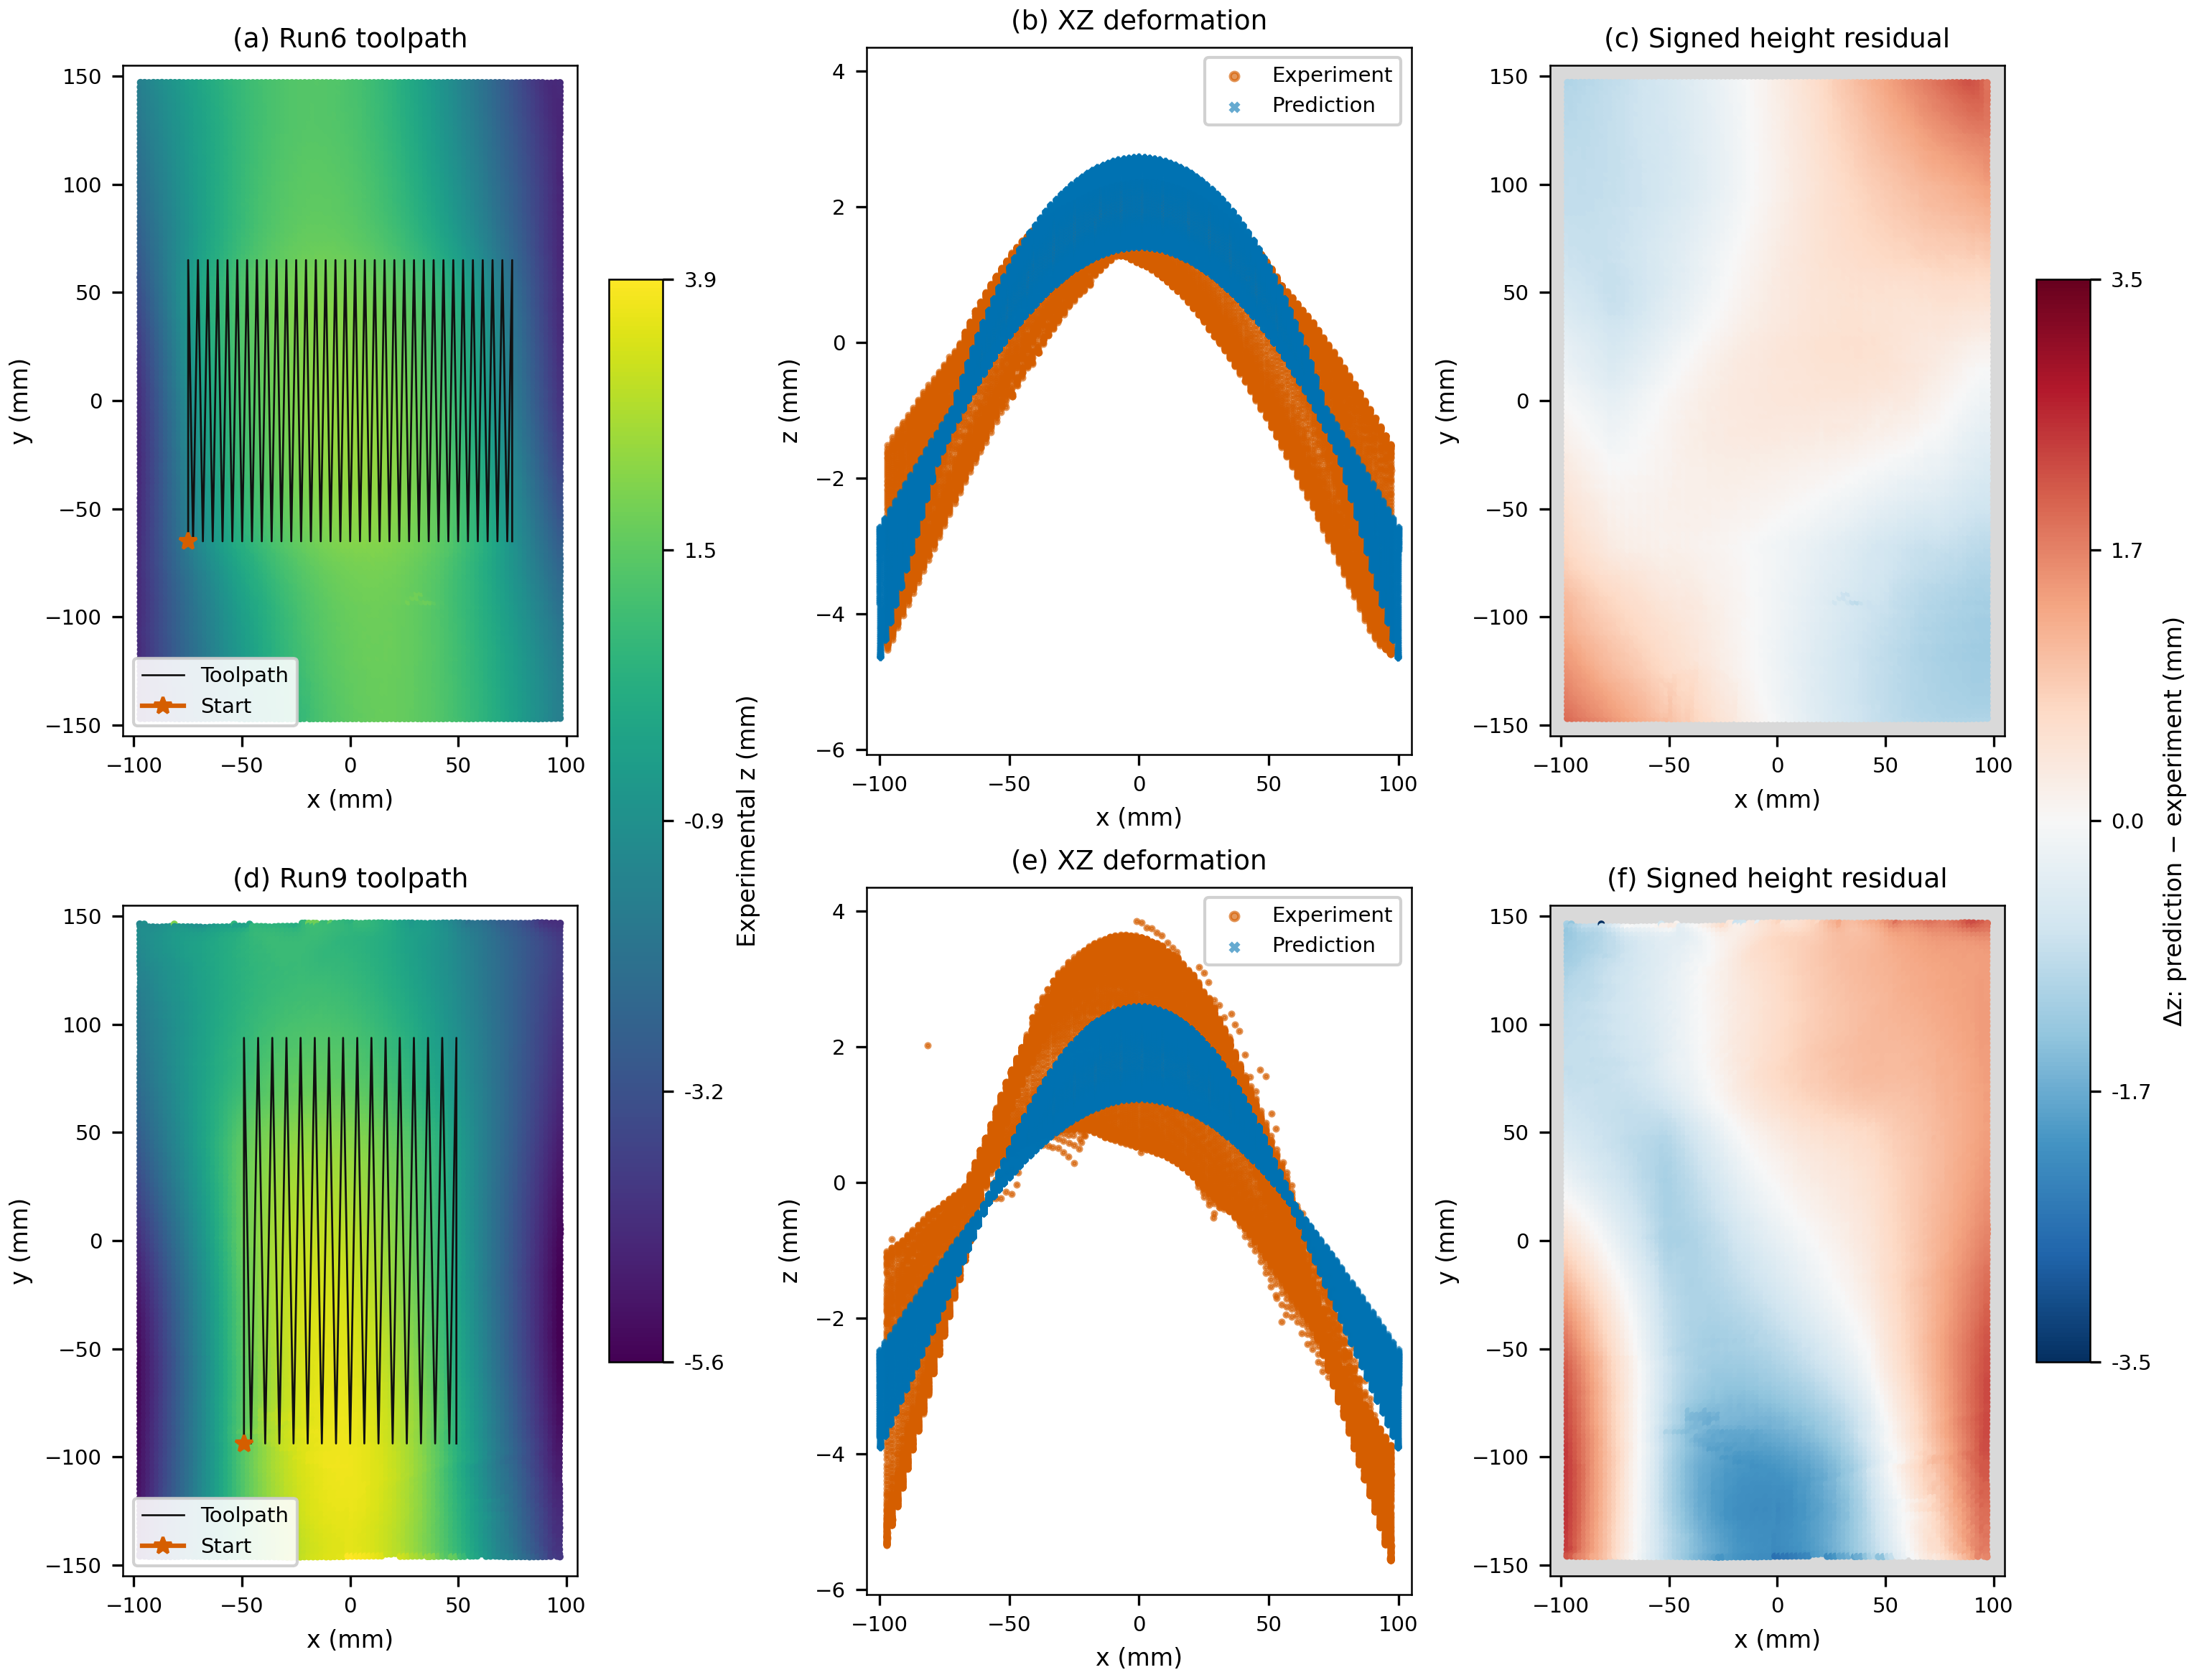

In [1]:
from IPython.display import Image, display
fig_2d_path = REPO_ROOT / "paper_figures/run6_run9_toolpath_deformation_residual.png"
display(Image(filename=str(fig_2d_path), width=900))


## 4. 3D Spatial Comparison: Isometric Surface Residuals & Profile Curvature
The 3D comparison figure visualizes the physical 3D saddle warpage and end-on profile:
- **Row 1 (Isometric Residual)**: True 3D triangulated surfaces colored by pointwise signed deviation $\Delta z \in [-2.5, +2.5]\text{ mm}$.
- **Row 2 (End-on Profile Overlay)**: Transverse curvature match along the forming midline, contrasting simulation (orange line) against raw optical scan points (blue scatter).


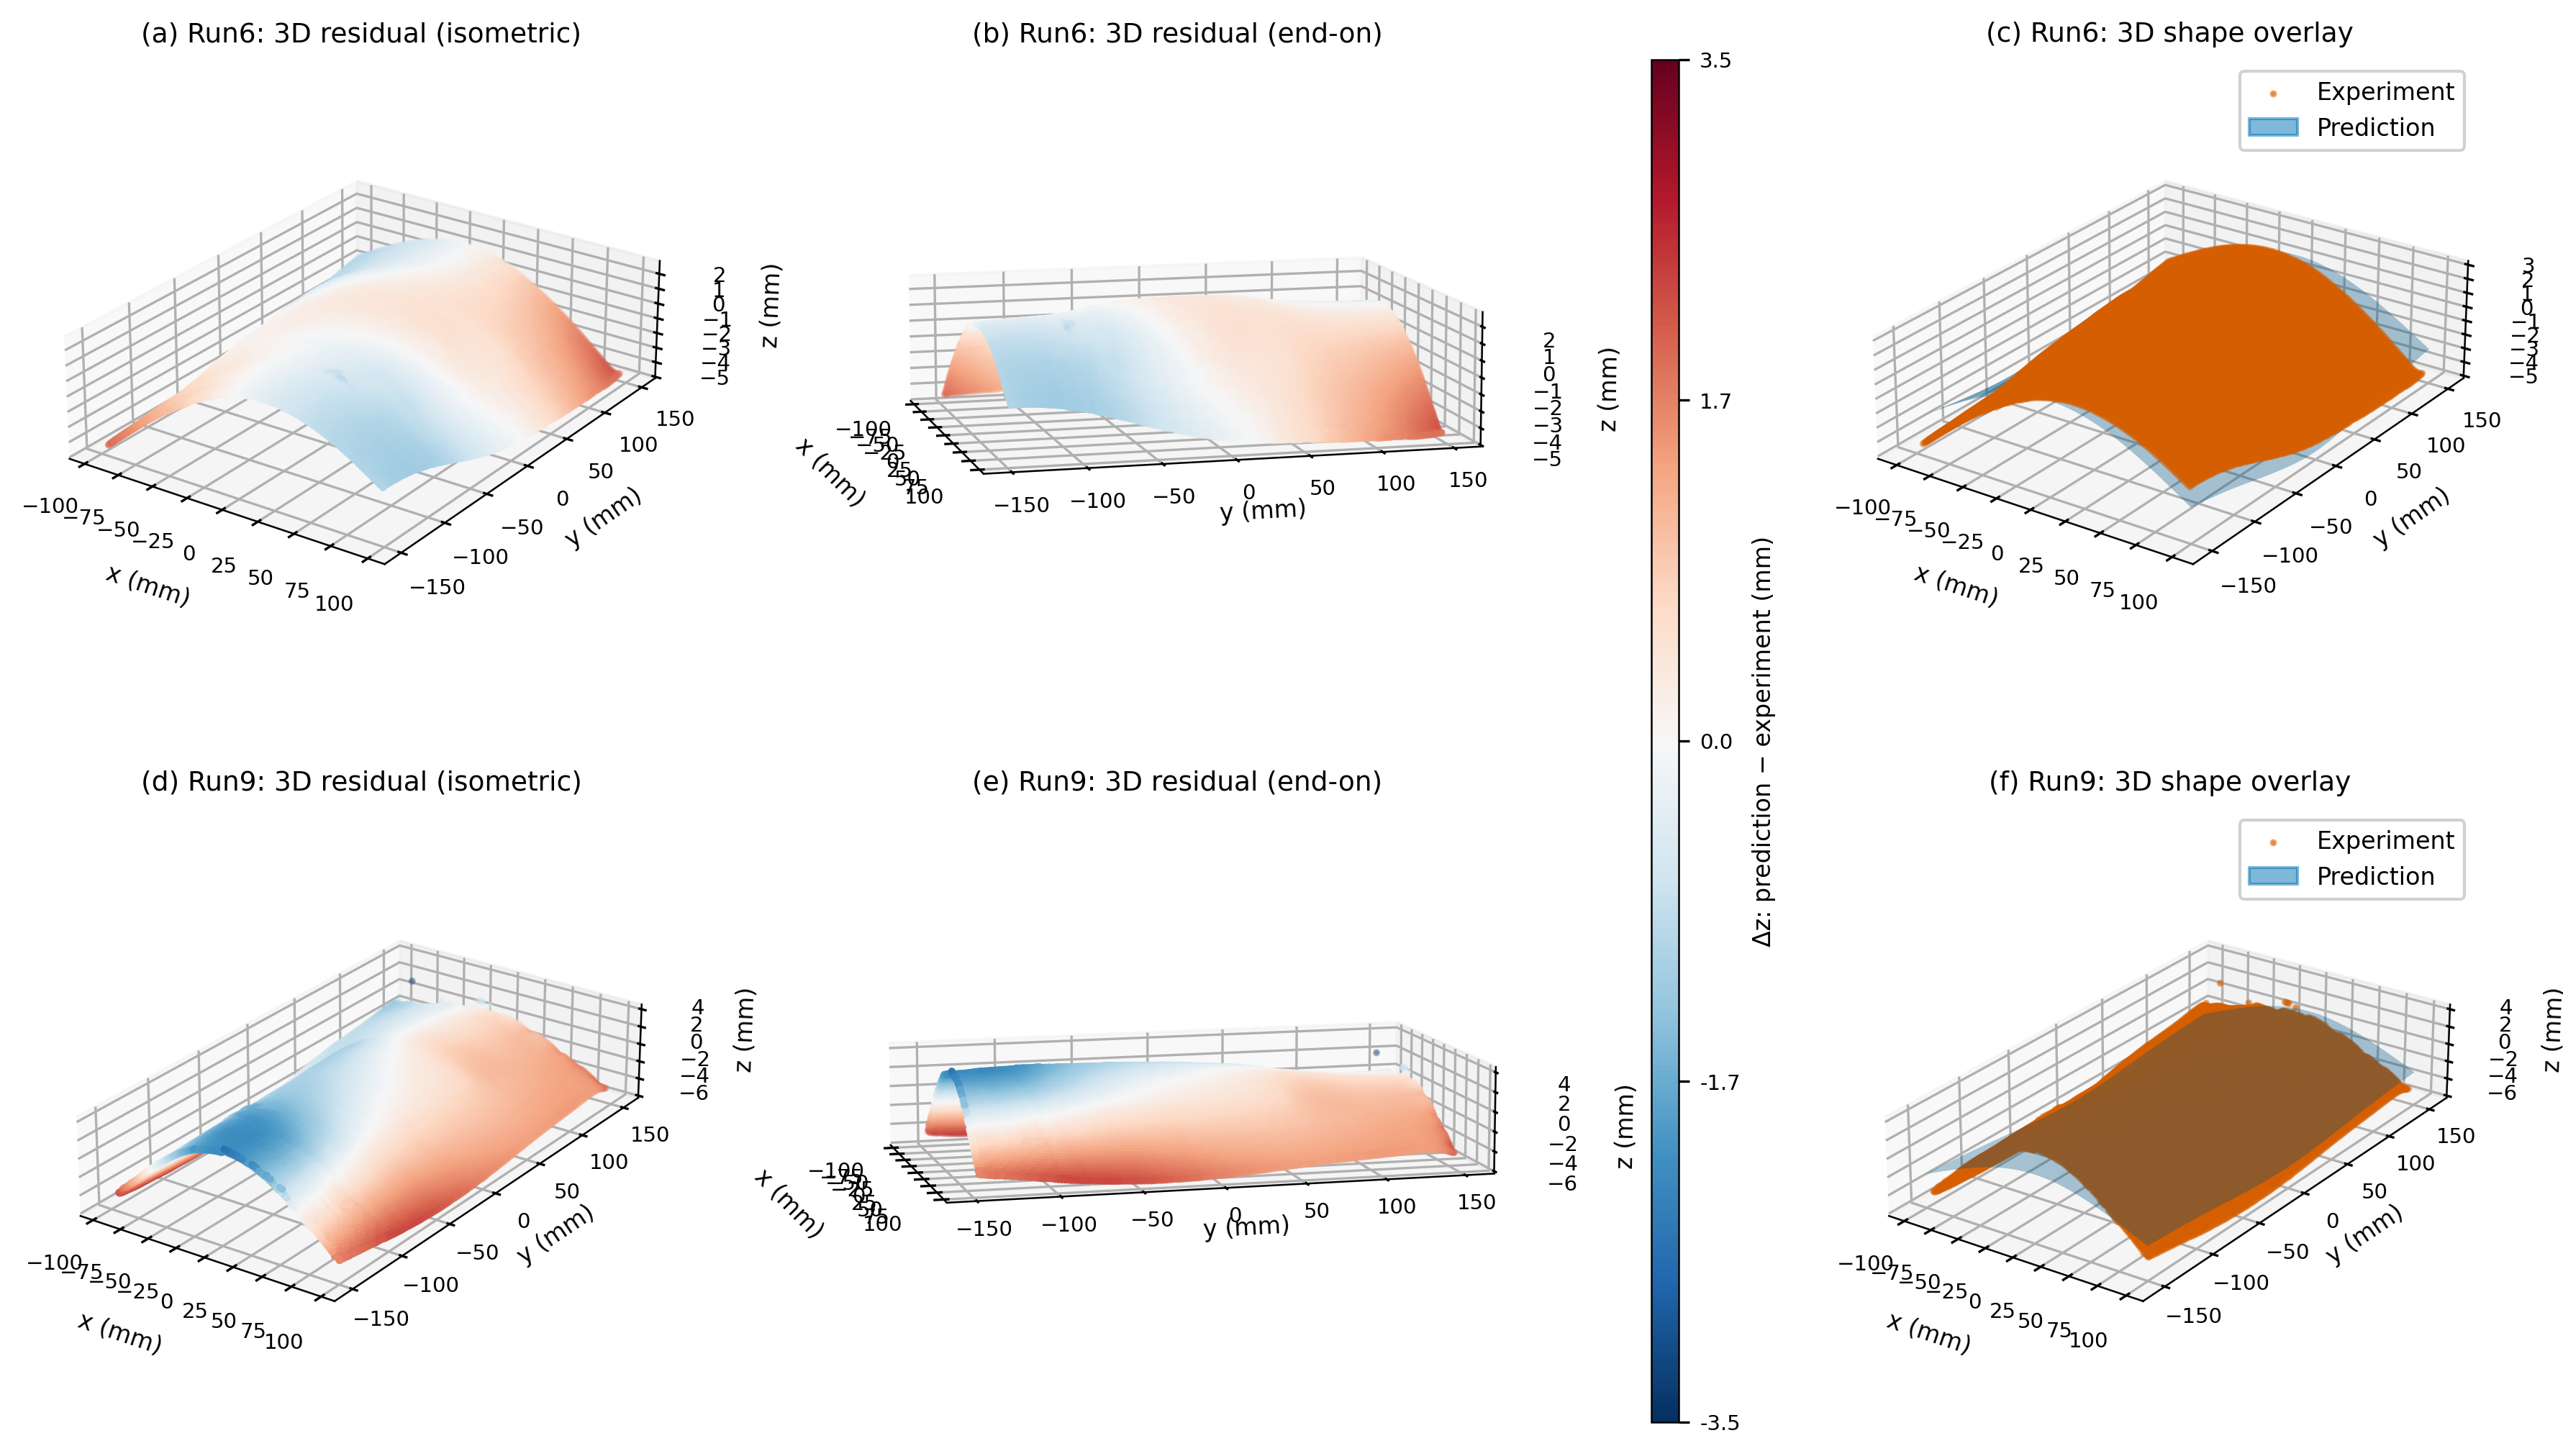

In [1]:
fig_3d_path = REPO_ROOT / "paper_figures/run6_run9_3d_deformation_residual.png"
display(Image(filename=str(fig_3d_path), width=900))


## 5. Summary & Key Findings
1. **Model Fidelity**: Calibrating the 4-parameter anisotropic bilayer model yields a **$1.185\text{ mm}$ symmetric RMS** on the training sheet (Run 6, $130 \times 130\text{ mm}$ span).
2. **Predictive Generalization**: Transferring the identical parameters to an independent sheet with a different toolpath density (Run 9, 33 passes) yields **$1.378\text{ mm}$ symmetric RMS** without any recalibration.
3. **Numerical Robustness**: The C++ native hybrid solver converged to machine precision ($1.5 \times 10^{-14}$) across all forming cycles with exact Hessian factorizations.
